# Supplementary Figure S5a. Hotspot and WGCNA program-score annotations: enrichment and joint τ*

S-LDSC heritability enrichment (left) and joint τ* (right) of trans-MaxPIP annotations built from four program scores (TransMap-local = WPC, TransPCO* = adapted TransPCO PC, Eigengene = PC1, AUCell) for Hotspot modules (top) and WGCNA modules (bottom). Enrichment is from single-annotation models (`sLDSC_WGCNA_Hotspot_Factor.rds`); joint τ* is from one joint model per module source containing the four annotations (`Joint_Hotspot_STATGEN2026`, `Joint_WGCNA_STATGEN2026`). Source: `Manu_Figures/Figure2.ipynb` cells 49-50. The dashed reference line is drawn at 0 for both metrics, as in the source code (the null value of enrichment is 1).

Error bars are estimate ± 1.9 × SE, exactly as in the source figure code (Figure2.ipynb uses 1.9, not 1.96; the caption's "95% confidence intervals" would be ± 1.96 × SE). Red asterisks mark nominal two-sided P < 0.05 with a positive estimate, again as in the source code; no multiple-testing correction is applied, although the caption says "FDR<5%". For reference the rds also has `fdr_bh`, a Benjamini–Hochberg adjustment across all tests of the same metric in this panel (not used for the stars). S-LDSC values are random-effects meta-analyses across traits (57 all, 18 brain, 22 blood; per-trait models conditional on the 53 baseline-LD annotations), recomputed here from the per-trait S-LDSC outputs; they match the summary rds read by the source notebook to machine precision. Enrichment P-values come from the h2-scaled enrichment statistic (author's `runSingleEnrMetaAnalysis`); the plotted estimate/SE is the meta-analysed S-LDSC Enrichment.

Caveat (Hotspot joint model): the per-trait S-LDSC regressions in `Joint_Hotspot_STATGEN2026_Remove_continuous` were run (16 May, 17:42) before that folder's LD scores were regenerated (18:12). The second annotation slot of the fitted model is labelled `WGCNA_aPC_Remove` in every `.results` file and its proportion of SNPs (1.004e-3) equals the WGCNA aPC annotation, not Hotspot aPC (2.181e-3). So the Hotspot "TransPCO*" joint τ* is the coefficient of the WGCNA TransPCO* annotation (scaled by the Hotspot TransPCO* SD), and the other three Hotspot joint estimates are conditional on WGCNA TransPCO*, not Hotspot TransPCO*. Values are shown as published; column `regression_category` records the annotation actually fitted.

Input: `data/Figure_S5a_program_score_sldsc.rds`.

In [1]:
library(ggplot2)
library(patchwork)
res <- readRDS("data/Figure_S5a_program_score_sldsc.rds")
res

metric,trait_set,trait,program_source,method,annotation_raw,regression_category,est,se,pvalue,fdr_bh,n_traits
<fct>,<chr>,<fct>,<fct>,<fct>,<glue>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<int>
Enrichment,all_traits,All traits (57),Hotspot,TransMap-local,Hotspot_wPC,NA,2.880688380,0.13918483,4.253659e-16,1.020878e-14,57
Enrichment,blood_traits,Blood-related traits (22),Hotspot,TransMap-local,Hotspot_wPC,NA,2.620053102,0.26007492,2.896798e-04,1.158719e-03,22
Enrichment,brain_traits,Brain-related traits (18),Hotspot,TransMap-local,Hotspot_wPC,NA,3.003577316,0.26800554,7.999808e-08,6.399846e-07,18
Enrichment,all_traits,All traits (57),Hotspot,TransPCO*,Hotspot_aPC,NA,2.568533256,0.22426087,1.577443e-06,7.571724e-06,57
Enrichment,blood_traits,Blood-related traits (22),Hotspot,TransPCO*,Hotspot_aPC,NA,2.768353415,0.42169017,1.017226e-02,2.822479e-02,22
Enrichment,brain_traits,Brain-related traits (18),Hotspot,TransPCO*,Hotspot_aPC,NA,2.372572396,0.50698119,1.058429e-02,2.822479e-02,18
Enrichment,all_traits,All traits (57),Hotspot,Eigengene,Hotspot_PC1,NA,1.462946039,0.51123348,3.020231e-01,4.832369e-01,57
Enrichment,blood_traits,Blood-related traits (22),Hotspot,Eigengene,Hotspot_PC1,NA,-0.165492405,0.93002549,3.426983e-01,4.930377e-01,22
Enrichment,brain_traits,Brain-related traits (18),Hotspot,Eigengene,Hotspot_PC1,NA,2.606716341,0.89931217,1.247305e-02,2.993533e-02,18


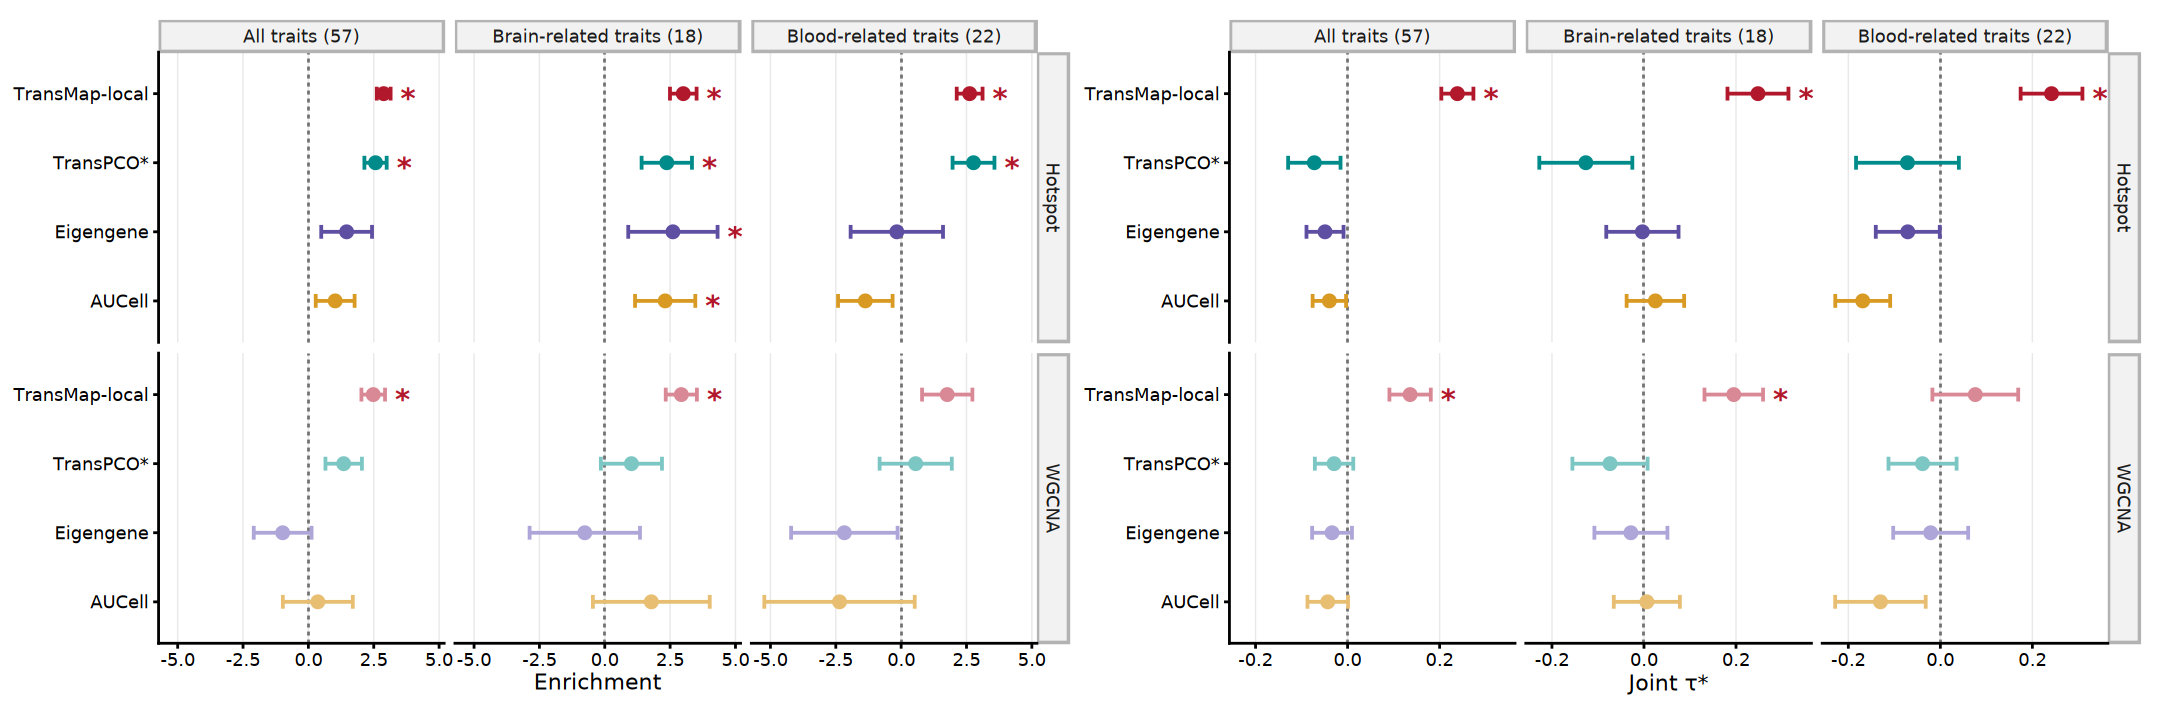

In [2]:
forest_row <- function(d, cols, xlab = NULL, vline = 0, show_strip = TRUE, facet_rows = NULL) {
  d$ci_low <- d$est - 1.9 * d$se; d$ci_high <- d$est + 1.9 * d$se
  d$star <- ifelse(d$pvalue < 0.05 & d$est > 0, "*", "")
  pad <- 0.04 * diff(range(c(d$ci_low, d$ci_high, vline)))
  p <- ggplot(d, aes(y = method, colour = colour_key)) +
    geom_vline(xintercept = vline, linetype = "dashed", colour = "grey45") +
    geom_errorbar(aes(xmin = ci_low, xmax = ci_high), width = 0.2, orientation = "y", linewidth = 0.8) +
    geom_point(aes(x = est), size = 3) +
    geom_text(aes(x = ci_high + pad, label = star), colour = "#B2182B", size = 6, fontface = "bold", hjust = 0, vjust = 0.7) +
    scale_colour_manual(values = cols, guide = "none") +
    scale_y_discrete(limits = rev) +
    labs(x = xlab, y = NULL) +
    theme_classic(base_size = 13) +
    theme(strip.background = element_rect(fill = "grey95", colour = "grey70"),
          panel.grid.major.x = element_line(colour = "grey91", linewidth = 0.3))
  p <- p + if (is.null(facet_rows)) facet_grid(. ~ trait) else facet_grid(reformulate("trait", facet_rows))
  if (!show_strip) p <- p + theme(strip.text.x = element_blank(), strip.background.x = element_blank())
  p
}

hot <- c("TransMap-local" = "#B2182B", "TransPCO*" = "#008B8B", "Eigengene" = "#5E4FA2", "AUCell" = "#D99A24")
wg  <- c("TransMap-local" = "#D98995", "TransPCO*" = "#7CC6C4", "Eigengene" = "#AEA6D9", "AUCell" = "#E7BE72")
cols <- c(setNames(hot, paste("Hotspot", names(hot))), setNames(wg, paste("WGCNA", names(wg))))
res$colour_key <- paste(res$program_source, res$method)
p_enr <- forest_row(subset(res, metric == "Enrichment"), cols, xlab = "Enrichment", facet_rows = "program_source")
p_jt  <- forest_row(subset(res, metric == "Joint tau*"), cols, xlab = expression("Joint " * tau * "*"), facet_rows = "program_source")
options(repr.plot.width = 18, repr.plot.height = 6)
p_enr | p_jt